In [1]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from spacy import displacy
from IPython.display import HTML, display
from pathlib import Path
from matplotlib.patches import Patch


# Get the current working directory of the notebook
notebook_dir = os.getcwd()
# Add the parent directory to the system path
sys.path.append(os.path.join(notebook_dir, '../'))

from data_processing import DataProcessing


In [2]:
pd.set_option('max_colwidth', 800)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [3]:
base_data_path = DataProcessing.load_base_data_path(notebook_dir)
llm_results_path = 'classification_results/naacl_2026_submission/tolsa_naacl_2026_2027-final/averaged/in_domain/llm/'
results_path = os.path.join(base_data_path, llm_results_path)
# results_path

In [4]:
results_root = (
    Path(results_path).resolve().parents[2]
    / "naacl_2026_submission"
)

experiment = "tolsa_naacl_2026_2027-final"
experiment_dir = results_root / experiment
averaged_dir = experiment_dir / "averaged"

seeds = [3, 7, 33]
embedding_model = "spacy_large"

print(f"Results root: {results_root}")
print(f"Experiment: {experiment_dir}")

Results root: /Users/detraviousjamaribrinkley/Documents/Development/research_labs/uf_ds/predictions/data/classification_results/naacl_2026_submission/tolsa_naacl_2026_2027-final/naacl_2026_submission
Experiment: /Users/detraviousjamaribrinkley/Documents/Development/research_labs/uf_ds/predictions/data/classification_results/naacl_2026_submission/tolsa_naacl_2026_2027-final/naacl_2026_submission/tolsa_naacl_2026_2027-final


In [5]:
results_root = Path(
    "../data/classification_results/naacl_2026_submission"
).resolve()

experiment_dir = results_root / experiment
averaged_dir = experiment_dir / "averaged"

## Base Results

In [6]:
def load_baseline_results(model_type, result_dir):
    records = []
    embedding_models = (
        ["spacy_small", "spacy_medium", "spacy_large"]
        if model_type == "glodd"
        else [None]
    )

    for seed in seeds:
        seed_dir = result_dir / f"seed{seed}"

        for embedding in embedding_models:
            if model_type == "glodd":
                search_dir = (
                    seed_dir / "in_domain"
                    / "glodd_hristova_step0" / embedding
                )
                target_file = "metrics_summary_glodd_step0.csv"
            elif model_type == "conll":
                search_dir = (
                    seed_dir / "in_domain" / "conll_2010_hedge_rule"
                )
                target_file = "metrics_summary_conll.csv"
            else:
                raise ValueError(f"Unsupported model type: {model_type}")

            if not search_dir.exists():
                print(f"Missing directory: {search_dir}")
                continue

            for metrics_file in search_dir.rglob(target_file):
                df = pd.read_csv(metrics_file)
                if df.empty:
                    continue

                for _, row in df.iterrows():
                    record = {
                        "seed": seed,
                        "model_type": model_type,
                        "model": embedding if model_type == "glodd" else row.get("model", model_type),
                    }

                    if embedding is not None:
                        record["embedding_model"] = embedding

                    for metric in [
                        "val_accuracy", "test_accuracy",
                        "val_precision_class_1", "val_recall_class_1",
                        "val_f1_class_1", "test_precision_class_1",
                        "test_recall_class_1", "test_f1_class_1",
                    ]:
                        if metric in df.columns:
                            record[metric] = pd.to_numeric(
                                row[metric], errors="coerce"
                            )

                    records.append(record)

    raw_df = pd.DataFrame(records)

    if raw_df.empty:
        print(f"No {model_type} results found.")
        return raw_df, raw_df, raw_df

    group_cols = ["model_type", "model"]
    if "embedding_model" in raw_df.columns:
        group_cols.append("embedding_model")

    metric_cols = [
        col for col in raw_df.select_dtypes(include=np.number).columns
        if col != "seed"
    ]

    summary_df = (
        raw_df.groupby(group_cols, as_index=False)
        .agg(
            **{metric: (metric, "mean") for metric in metric_cols},
            n_seeds=("seed", "nunique"),
        )
    )

    std_df = (
        raw_df.groupby(group_cols)[metric_cols]
        .std()
        .reset_index()
    )

    return raw_df, summary_df, std_df


glodd_raw, glodd_summary, glodd_std = load_baseline_results(
    "glodd", experiment_dir
)

conll_raw, conll_summary, conll_std = load_baseline_results(
    "conll", experiment_dir
)

display(glodd_raw)
display(glodd_summary)
display(conll_raw)
display(conll_summary)

,seed,model_type,model,embedding_model,val_accuracy,test_accuracy,val_precision_class_1,val_recall_class_1,val_f1_class_1,test_precision_class_1,test_recall_class_1,test_f1_class_1
0,3,glodd,spacy_small,spacy_small,0.714814,0.710006,0.911353,0.450769,0.603191,0.905024,0.443462,0.595250
1,3,glodd,spacy_medium,spacy_medium,0.717588,0.713704,0.911111,0.457308,0.608963,0.908385,0.450000,0.601852
2,3,glodd,spacy_large,spacy_large,0.722582,0.717773,0.914781,0.466538,0.617932,0.908676,0.459231,0.610118
3,7,glodd,spacy_small,spacy_small,0.718698,0.710560,0.905944,0.463077,0.612879,0.902098,0.446538,0.597376
4,7,glodd,spacy_medium,spacy_medium,0.720178,0.712595,0.905900,0.466538,0.615892,0.901690,0.451538,0.601743
5,7,glodd,spacy_large,spacy_large,0.724246,0.717773,0.907421,0.475000,0.623580,0.904977,0.461538,0.611309
6,33,glodd,spacy_small,spacy_small,0.715554,0.713889,0.898051,0.460769,0.609049,0.907823,0.450769,0.602416
7,33,glodd,spacy_medium,spacy_medium,0.717588,0.716849,0.899479,0.464615,0.612731,0.908952,0.456923,0.608139
8,33,glodd,spacy_large,spacy_large,0.722212,0.721657,0.901903,0.473846,0.621281,0.910112,0.467308,0.617535


,model_type,model,embedding_model,val_accuracy,test_accuracy,val_precision_class_1,val_recall_class_1,val_f1_class_1,test_precision_class_1,test_recall_class_1,test_f1_class_1,n_seeds
0,glodd,spacy_large,spacy_large,0.723013,0.719068,0.908035,0.471795,0.620931,0.907922,0.462692,0.612987,3
1,glodd,spacy_medium,spacy_medium,0.718451,0.714383,0.905497,0.462821,0.612529,0.906342,0.452821,0.603911,3
2,glodd,spacy_small,spacy_small,0.716355,0.711485,0.905116,0.458205,0.608373,0.904982,0.446923,0.598347,3


,seed,model_type,model,val_accuracy,test_accuracy,val_precision_class_1,val_recall_class_1,val_f1_class_1,test_precision_class_1,test_recall_class_1,test_f1_class_1
0,3,conll,conll_2010_hedge_rule,0.720547,0.718698,0.728685,0.667308,0.696647,0.732643,0.653462,0.690791
1,7,conll,conll_2010_hedge_rule,0.718698,0.708896,0.730654,0.657308,0.692043,0.717557,0.650769,0.682533
2,33,conll,conll_2010_hedge_rule,0.728685,0.719253,0.741784,0.668462,0.703217,0.725982,0.668462,0.696035


,model_type,model,val_accuracy,test_accuracy,val_precision_class_1,val_recall_class_1,val_f1_class_1,test_precision_class_1,test_recall_class_1,test_f1_class_1,n_seeds
0,conll,conll_2010_hedge_rule,0.722643,0.715616,0.733708,0.664359,0.697302,0.725394,0.657564,0.689786,3


In [7]:
glodd_raw = glodd_raw[
    ["seed", "model_type", "embedding_model",
     "val_accuracy", "test_accuracy",
     "val_precision_class_1", "val_recall_class_1", "val_f1_class_1",
     "test_precision_class_1", "test_recall_class_1", "test_f1_class_1"]
]

display(glodd_raw)
display(glodd_summary)

,seed,model_type,embedding_model,val_accuracy,test_accuracy,val_precision_class_1,val_recall_class_1,val_f1_class_1,test_precision_class_1,test_recall_class_1,test_f1_class_1
0,3,glodd,spacy_small,0.714814,0.710006,0.911353,0.450769,0.603191,0.905024,0.443462,0.595250
1,3,glodd,spacy_medium,0.717588,0.713704,0.911111,0.457308,0.608963,0.908385,0.450000,0.601852
2,3,glodd,spacy_large,0.722582,0.717773,0.914781,0.466538,0.617932,0.908676,0.459231,0.610118
3,7,glodd,spacy_small,0.718698,0.710560,0.905944,0.463077,0.612879,0.902098,0.446538,0.597376
4,7,glodd,spacy_medium,0.720178,0.712595,0.905900,0.466538,0.615892,0.901690,0.451538,0.601743
5,7,glodd,spacy_large,0.724246,0.717773,0.907421,0.475000,0.623580,0.904977,0.461538,0.611309
6,33,glodd,spacy_small,0.715554,0.713889,0.898051,0.460769,0.609049,0.907823,0.450769,0.602416
7,33,glodd,spacy_medium,0.717588,0.716849,0.899479,0.464615,0.612731,0.908952,0.456923,0.608139
8,33,glodd,spacy_large,0.722212,0.721657,0.901903,0.473846,0.621281,0.910112,0.467308,0.617535


,model_type,model,embedding_model,val_accuracy,test_accuracy,val_precision_class_1,val_recall_class_1,val_f1_class_1,test_precision_class_1,test_recall_class_1,test_f1_class_1,n_seeds
0,glodd,spacy_large,spacy_large,0.723013,0.719068,0.908035,0.471795,0.620931,0.907922,0.462692,0.612987,3
1,glodd,spacy_medium,spacy_medium,0.718451,0.714383,0.905497,0.462821,0.612529,0.906342,0.452821,0.603911,3
2,glodd,spacy_small,spacy_small,0.716355,0.711485,0.905116,0.458205,0.608373,0.904982,0.446923,0.598347,3


In [8]:
models = [
    "gpt-oss-20b",
    "llama-3.3-70b-instruct",
    "mistral-small-3.1",
]

model_labels = {
    "gpt-oss-20b": "GPT-OSS-20B",
    "llama-3.3-70b-instruct": "Llama-3.3-70B",
    "mistral-small-3.1": "Mistral-Small-3.1",
}

prompt_labels = {
    "zero-shot": "ZS",
    "chain-of-thought": "CoT",
}

llm_records = []

for seed in seeds:
    llm_dir = (
        experiment_dir / f"seed{seed}" / "in_domain" / "llm"
    )

    for model in models:
        model_dir = llm_dir / model

        if not model_dir.exists():
            continue

        for prompt in prompt_labels:
            metrics_file = (
                model_dir / prompt / "test"
                / f"metrics_summary_{model}_{prompt}.csv"
            )

            if not metrics_file.exists():
                continue

            df = pd.read_csv(metrics_file)

            for _, row in df.iterrows():
                llm_records.append({
                    "seed": seed,
                    "model": model,
                    "prompt_type": prompt,
                    "test_accuracy": row.get("test_accuracy", np.nan),
                    "macro_f1": np.mean([
                        row.get("f1_class_0", np.nan),
                        row.get("f1_class_1", np.nan),
                    ]),
                })

llm_seed_results = pd.DataFrame(llm_records)

llm_summary = (
    llm_seed_results
    .groupby(["model", "prompt_type"], as_index=False)
    .agg(
        test_accuracy=("test_accuracy", "mean"),
        test_accuracy_std=("test_accuracy", "std"),
        macro_f1=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),
        n_seeds=("seed", "nunique"),
    )
)

llm_summary["model_label"] = llm_summary["model"].map(model_labels)
llm_summary["prompt_label"] = llm_summary["prompt_type"].map(prompt_labels)

display(llm_seed_results)
display(llm_summary)

,seed,model,prompt_type,test_accuracy,macro_f1
0,3,gpt-oss-20b,zero-shot,0.850934,0.850824
1,3,gpt-oss-20b,chain-of-thought,0.858887,0.858883
2,3,llama-3.3-70b-instruct,zero-shot,0.868134,0.867676
3,3,llama-3.3-70b-instruct,chain-of-thought,0.888663,0.888649
4,3,mistral-small-3.1,zero-shot,0.823932,0.822997
5,3,mistral-small-3.1,chain-of-thought,0.832439,0.831762
6,7,gpt-oss-20b,zero-shot,0.858332,0.858292
7,7,gpt-oss-20b,chain-of-thought,0.858702,0.858702
8,7,llama-3.3-70b-instruct,zero-shot,0.868689,0.868281
9,7,mistral-small-3.1,zero-shot,0.826336,0.825510


,model,prompt_type,test_accuracy,test_accuracy_std,macro_f1,macro_f1_std,n_seeds,model_label,prompt_label
0,gpt-oss-20b,chain-of-thought,0.859072,0.000489,0.859070,0.000490,3,GPT-OSS-20B,CoT
1,gpt-oss-20b,zero-shot,0.855866,0.004271,0.855782,0.004294,3,GPT-OSS-20B,ZS
2,llama-3.3-70b-instruct,chain-of-thought,0.888663,NaN,0.888649,NaN,1,Llama-3.3-70B,CoT
3,llama-3.3-70b-instruct,zero-shot,0.864373,0.006999,0.863918,0.007038,3,Llama-3.3-70B,ZS
4,mistral-small-3.1,chain-of-thought,0.848167,0.023352,0.847077,0.022586,3,Mistral-Small-3.1,CoT
5,mistral-small-3.1,zero-shot,0.824363,0.001796,0.823472,0.001847,3,Mistral-Small-3.1,ZS


## Convert Table to LaTex

In [9]:
# =====================================================
# ML Model Results
# =====================================================

embedding_models = {
    "spacy_small": "spaCy-S",
    "spacy_medium": "spaCy-M",
    "spacy_large": "spaCy-L",
    "st_distilroberta": "ST-DR",
    "st_minilm_l12": "ST-ML12",
    "st_minilm_l6": "ST-ML6",
    "st_mpnet_base": "ST-MPNet",
}

ml_records = []

for seed in seeds:
    seed_dir = experiment_dir / f"seed{seed}" / "in_domain"

    for embedding, model_label in embedding_models.items():
        metrics_file = (
            seed_dir / embedding / "metrics_summary_ml_models.csv"
        )

        if not metrics_file.exists():
            print(f"Missing: {metrics_file}")
            continue

        df = pd.read_csv(metrics_file)

        if df.empty:
            continue

        for _, row in df.iterrows():
            f1_0 = pd.to_numeric(row.get("f1_class_0", np.nan), errors="coerce")
            f1_1 = pd.to_numeric(row.get("f1_class_1", np.nan), errors="coerce")

            ml_records.append({
                "seed": seed,
                "model": embedding,
                "model_label": model_label,
                "test_accuracy": pd.to_numeric(
                    row.get("test_accuracy", np.nan), errors="coerce"
                ),
                "macro_f1": np.mean([f1_0, f1_1]),
            })

ml_seed_results = pd.DataFrame(ml_records)

ml_summary = (
    ml_seed_results
    .groupby(["model", "model_label"], as_index=False)
    .agg(
        test_accuracy=("test_accuracy", "mean"),
        test_accuracy_std=("test_accuracy", "std"),
        macro_f1=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),
        n_seeds=("seed", "nunique"),
    )
)

display(ml_seed_results)
display(ml_summary)

,seed,model,model_label,test_accuracy,macro_f1
0,3,spacy_small,spaCy-S,0.779175,0.779170
1,3,spacy_small,spaCy-S,0.827076,0.827059
2,3,spacy_small,spaCy-S,0.835584,0.835384
3,3,spacy_small,spaCy-S,0.827816,0.827697
4,3,spacy_small,spaCy-S,0.777696,0.777565
5,3,spacy_small,spaCy-S,0.860736,0.857974
6,3,spacy_small,spaCy-S,0.855373,0.854350
7,3,spacy_small,spaCy-S,0.837803,0.837553
8,3,spacy_small,spaCy-S,0.873867,0.872991
9,3,spacy_medium,spaCy-M,0.651313,0.620736


,model,model_label,test_accuracy,test_accuracy_std,macro_f1,macro_f1_std,n_seeds
0,spacy_large,spaCy-L,0.870765,0.031612,0.870255,0.031517,3
1,spacy_medium,spaCy-M,0.826999,0.052739,0.823701,0.058636,3
2,spacy_small,spaCy-S,0.837159,0.028766,0.836531,0.028377,3
3,st_distilroberta,ST-DR,0.888094,0.034846,0.887554,0.034896,3
4,st_minilm_l12,ST-ML12,0.885245,0.033481,0.884691,0.033498,3
5,st_minilm_l6,ST-ML6,0.872805,0.039903,0.871932,0.040944,3
6,st_mpnet_base,ST-MPNet,0.887601,0.032741,0.887214,0.032734,3


## BERT: Base and Large

In [15]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# Load BERT results
results_dir = Path(
    "../data/classification_results/naacl_2026_submission/"
    "tolsa_naacl_2026_2027-final/averaged/in_domain"
)

bert_files = {
    "BERT-Base": results_dir / "bert_base" / "mean_std.csv",
    "BERT-Large": results_dir / "bert_large" / "mean_std.csv",
}

bert_tables = []

for model, filepath in bert_files.items():
    if not filepath.exists():
        print(f"Missing file: {filepath.resolve()}")
        continue

    df = pd.read_csv(filepath)
    print(f"\n{model}: {filepath.resolve()}")
    print(f"Shape: {df.shape}")
    print("Columns:", df.columns.tolist())

    df.insert(0, "Embedding", model)
    bert_tables.append(df)

# Combine into one DataFrame
if bert_tables:
    bert_comparison = pd.concat(bert_tables, ignore_index=True)

    display(bert_comparison)

    # Convert the DataFrame to LaTeX
    bert_latex = bert_comparison.to_latex(
        index=False,
        float_format="%.4f",
        na_rep="—",
        escape=True,
    )

    print(bert_latex)
else:
    print("No BERT results loaded. Check the paths above.")


BERT-Base: /Users/detraviousjamaribrinkley/Documents/Development/research_labs/uf_ds/predictions/data/classification_results/naacl_2026_submission/tolsa_naacl_2026_2027-final/averaged/in_domain/bert_base/mean_std.csv
Shape: (4, 29)
Columns: ['seed', 'model', 'train_accuracy', 'val_accuracy', 'test_accuracy', 'train_precision_class_0', 'train_precision_class_1', 'val_precision_class_0', 'val_precision_class_1', 'test_precision_class_0', 'test_precision_class_1', 'train_recall_class_0', 'train_recall_class_1', 'val_recall_class_0', 'val_recall_class_1', 'test_recall_class_0', 'test_recall_class_1', 'train_f1_class_0', 'train_f1_class_1', 'val_f1_class_0', 'val_f1_class_1', 'test_f1_class_0', 'test_f1_class_1', 'train_roc_auc', 'val_roc_auc', 'test_roc_auc', 'train_pr_auc', 'val_pr_auc', 'test_pr_auc']

BERT-Large: /Users/detraviousjamaribrinkley/Documents/Development/research_labs/uf_ds/predictions/data/classification_results/naacl_2026_submission/tolsa_naacl_2026_2027-final/averaged/in

,Embedding,seed,model,train_accuracy,val_accuracy,test_accuracy,train_precision_class_0,train_precision_class_1,val_precision_class_0,val_precision_class_1,test_precision_class_0,test_precision_class_1,train_recall_class_0,train_recall_class_1,val_recall_class_0,val_recall_class_1,test_recall_class_0,test_recall_class_1,train_f1_class_0,train_f1_class_1,val_f1_class_0,val_f1_class_1,test_f1_class_0,test_f1_class_1,train_roc_auc,val_roc_auc,test_roc_auc,train_pr_auc,val_pr_auc,test_pr_auc
0,BERT-Base,3,tolsa-bert_base,0.9928,0.9371,0.9345,0.9935,0.9922,0.9426,0.9313,0.9388,0.9299,0.9928,0.9929,0.9359,0.9385,0.9348,0.9342,0.9931,0.9926,0.9392,0.9349,0.9368,0.9321,0.9996,0.9848,0.9844,0.9996,0.9861,0.9856
1,BERT-Base,7,tolsa-bert_base,0.9917,0.9390,0.9336,0.9909,0.9927,0.9431,0.9345,0.9368,0.9301,0.9932,0.9901,0.9391,0.9388,0.9352,0.9319,0.9921,0.9914,0.9411,0.9367,0.9360,0.9310,0.9990,0.9858,0.9853,0.9991,0.9866,0.9858
2,BERT-Base,33,tolsa-bert_base,0.9933,0.9384,0.9371,0.9932,0.9935,0.9421,0.9345,0.9376,0.9366,0.9939,0.9927,0.9391,0.9377,0.9416,0.9323,0.9936,0.9931,0.9406,0.9361,0.9396,0.9345,0.9996,0.9848,0.9841,0.9996,0.9857,0.9851
3,BERT-Base,Average,tolsa-bert_base,0.9926 ± 0.0008,0.9382 ± 0.0009,0.9351 ± 0.0018,0.9925 ± 0.0014,0.9928 ± 0.0006,0.9426 ± 0.0005,0.9334 ± 0.0018,0.9377 ± 0.0010,0.9322 ± 0.0038,0.9933 ± 0.0006,0.9919 ± 0.0016,0.9380 ± 0.0019,0.9383 ± 0.0006,0.9372 ± 0.0038,0.9328 ± 0.0012,0.9929 ± 0.0008,0.9923 ± 0.0009,0.9403 ± 0.0010,0.9359 ± 0.0009,0.9375 ± 0.0019,0.9325 ± 0.0018,0.9994 ± 0.0004,0.9851 ± 0.0006,0.9846 ± 0.0006,0.9994 ± 0.0003,0.9862 ± 0.0005,0.9855 ± 0.0004
4,BERT-Large,3,tolsa-bert_large,0.9946,0.9371,0.9392,0.9957,0.9935,0.9401,0.9339,0.9441,0.9339,0.9939,0.9954,0.9387,0.9354,0.9384,0.9400,0.9948,0.9944,0.9394,0.9347,0.9412,0.9369,0.9998,0.9837,0.9839,0.9998,0.9840,0.9835
5,BERT-Large,7,tolsa-bert_large,0.9959,0.9392,0.9388,0.9958,0.9959,0.9403,0.9379,0.9399,0.9375,0.9962,0.9955,0.9426,0.9354,0.9423,0.9350,0.9960,0.9957,0.9415,0.9366,0.9411,0.9363,0.9998,0.9850,0.9846,0.9998,0.9862,0.9857
6,BERT-Large,33,tolsa-bert_large,0.9950,0.9403,0.9392,0.9960,0.9940,0.9404,0.9401,0.9416,0.9366,0.9944,0.9956,0.9448,0.9354,0.9412,0.9369,0.9952,0.9948,0.9426,0.9377,0.9414,0.9367,0.9997,0.9853,0.9851,0.9998,0.9866,0.9863
7,BERT-Large,Average,tolsa-bert_large,0.9952 ± 0.0006,0.9388 ± 0.0016,0.9390 ± 0.0002,0.9958 ± 0.0001,0.9945 ± 0.0013,0.9403 ± 0.0002,0.9373 ± 0.0031,0.9419 ± 0.0021,0.9360 ± 0.0019,0.9949 ± 0.0012,0.9955 ± 0.0001,0.9420 ± 0.0031,0.9354 ± 0.0000,0.9406 ± 0.0020,0.9373 ± 0.0025,0.9953 ± 0.0006,0.9950 ± 0.0007,0.9412 ± 0.0016,0.9363 ± 0.0016,0.9412 ± 0.0001,0.9366 ± 0.0003,0.9998 ± 0.0001,0.9847 ± 0.0008,0.9845 ± 0.0006,0.9998 ± 0.0000,0.9856 ± 0.0014,0.9852 ± 0.0014


\begin{tabular}{llllllllllllllllllllllllllllll}
\toprule
Embedding & seed & model & train\_accuracy & val\_accuracy & test\_accuracy & train\_precision\_class\_0 & train\_precision\_class\_1 & val\_precision\_class\_0 & val\_precision\_class\_1 & test\_precision\_class\_0 & test\_precision\_class\_1 & train\_recall\_class\_0 & train\_recall\_class\_1 & val\_recall\_class\_0 & val\_recall\_class\_1 & test\_recall\_class\_0 & test\_recall\_class\_1 & train\_f1\_class\_0 & train\_f1\_class\_1 & val\_f1\_class\_0 & val\_f1\_class\_1 & test\_f1\_class\_0 & test\_f1\_class\_1 & train\_roc\_auc & val\_roc\_auc & test\_roc\_auc & train\_pr\_auc & val\_pr\_auc & test\_pr\_auc \\
\midrule
BERT-Base & 3 & tolsa-bert\_base & 0.9928 & 0.9371 & 0.9345 & 0.9935 & 0.9922 & 0.9426 & 0.9313 & 0.9388 & 0.9299 & 0.9928 & 0.9929 & 0.9359 & 0.9385 & 0.9348 & 0.9342 & 0.9931 & 0.9926 & 0.9392 & 0.9349 & 0.9368 & 0.9321 & 0.9996 & 0.9848 & 0.9844 & 0.9996 & 0.9861 & 0.9856 \\
BERT-Base & 7 & tolsa-bert\_base 

## Plot Glodd (spaCy) + CoNLL + ML (spaCy) + ML (SentenceTransformer) + LLM (Zero-Shot) + LLM (CoT)

BERT columns: ['Embedding', 'seed', 'model', 'train_accuracy', 'val_accuracy', 'test_accuracy', 'train_precision_class_0', 'train_precision_class_1', 'val_precision_class_0', 'val_precision_class_1', 'test_precision_class_0', 'test_precision_class_1', 'train_recall_class_0', 'train_recall_class_1', 'val_recall_class_0', 'val_recall_class_1', 'test_recall_class_0', 'test_recall_class_1', 'train_f1_class_0', 'train_f1_class_1', 'val_f1_class_0', 'val_f1_class_1', 'test_f1_class_0', 'test_f1_class_1', 'train_roc_auc', 'val_roc_auc', 'test_roc_auc', 'train_pr_auc', 'val_pr_auc', 'test_pr_auc']


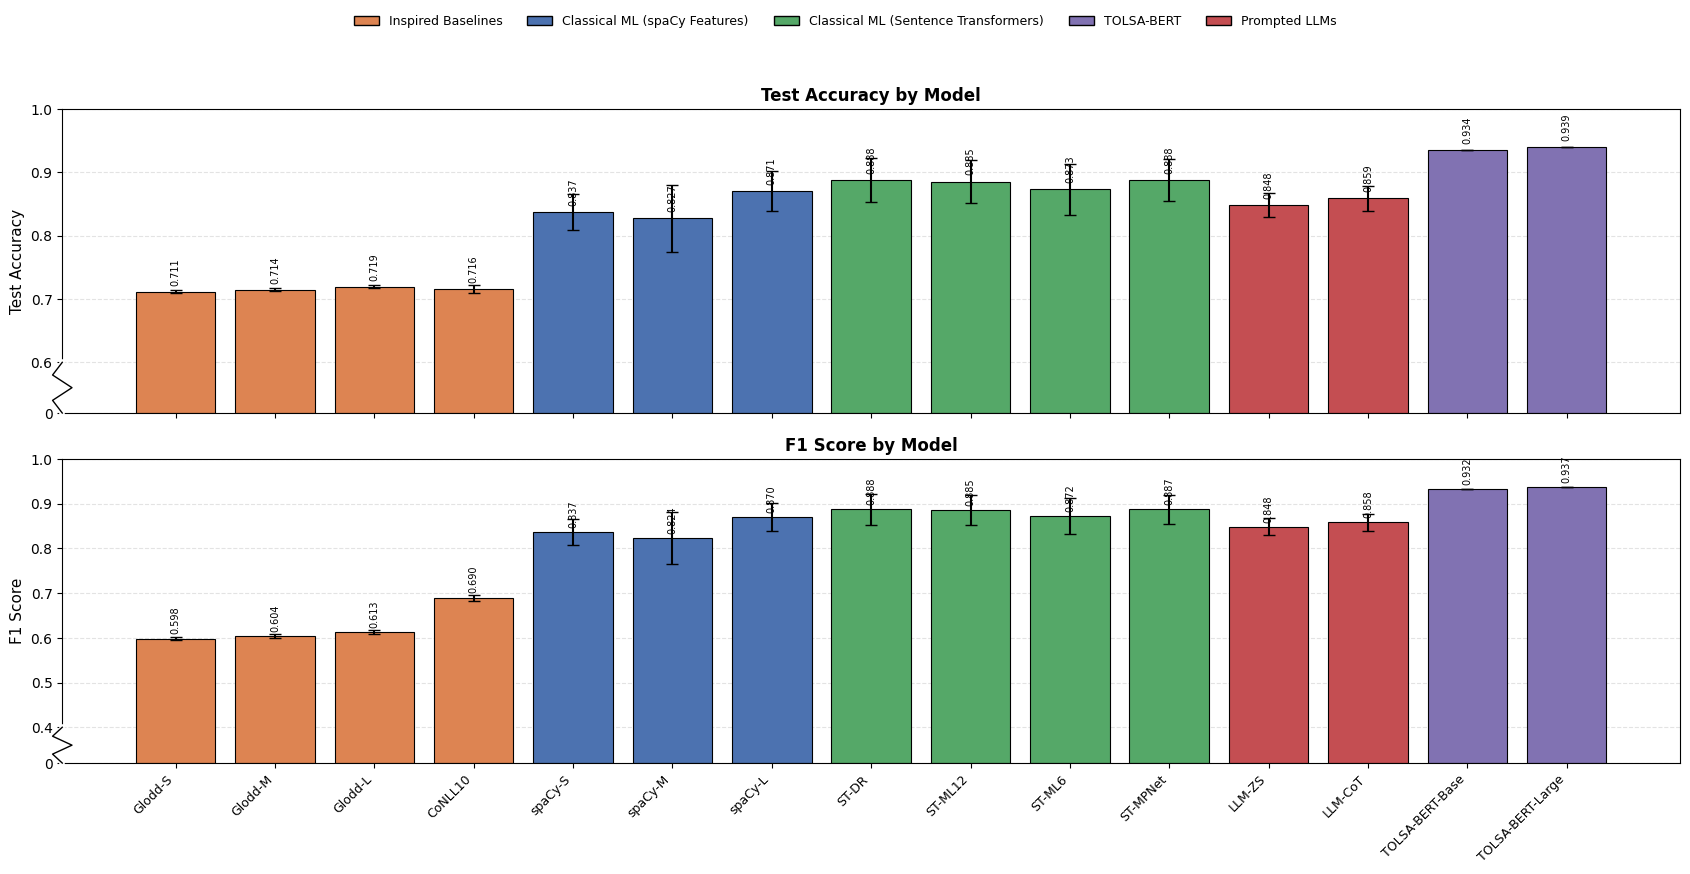

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

# =====================================================
# Build Individual Model Results from Existing DataFrames
# =====================================================

plot_records = []

# GloDD
glodd_labels = {
    "spacy_small": "Glodd-S",
    "spacy_medium": "Glodd-M",
    "spacy_large": "Glodd-L",
}

for _, row in glodd_summary.iterrows():
    embedding = row["embedding_model"]
    std_row = glodd_std[glodd_std["embedding_model"] == embedding]

    if {"test_f1_class_0", "test_f1_class_1"}.issubset(glodd_summary.columns):
        f1_value = np.mean([row["test_f1_class_0"], row["test_f1_class_1"]])
        f1_sd = (
            np.sqrt(
                std_row["test_f1_class_0"].iloc[0] ** 2
                + std_row["test_f1_class_1"].iloc[0] ** 2
            ) / 2
            if not std_row.empty else np.nan
        )
    else:
        f1_value = row.get("test_f1_class_1", np.nan)
        f1_sd = (
            std_row["test_f1_class_1"].iloc[0]
            if not std_row.empty and "test_f1_class_1" in std_row.columns
            else np.nan
        )

    plot_records.append({
        "Model": glodd_labels[embedding],
        "Accuracy": row.get("test_accuracy", np.nan),
        "Accuracy SD": (
            std_row["test_accuracy"].iloc[0]
            if not std_row.empty else np.nan
        ),
        "Macro F1": f1_value,
        "Macro F1 SD": f1_sd,
    })

# CoNLL
for _, row in conll_summary.iterrows():
    model_value = row.get("model", "conll")
    std_row = conll_std[conll_std["model"] == model_value]

    if {"test_f1_class_0", "test_f1_class_1"}.issubset(conll_summary.columns):
        f1_value = np.mean([row["test_f1_class_0"], row["test_f1_class_1"]])
        f1_sd = (
            np.sqrt(
                std_row["test_f1_class_0"].iloc[0] ** 2
                + std_row["test_f1_class_1"].iloc[0] ** 2
            ) / 2
            if not std_row.empty else np.nan
        )
    else:
        f1_value = row.get("test_f1_class_1", np.nan)
        f1_sd = (
            std_row["test_f1_class_1"].iloc[0]
            if not std_row.empty and "test_f1_class_1" in std_row.columns
            else np.nan
        )

    plot_records.append({
        "Model": "CoNLL10",
        "Accuracy": row.get("test_accuracy", np.nan),
        "Accuracy SD": (
            std_row["test_accuracy"].iloc[0]
            if not std_row.empty else np.nan
        ),
        "Macro F1": f1_value,
        "Macro F1 SD": f1_sd,
    })

# ML
ml_labels = {
    "spacy_small": "spaCy-S",
    "spacy_medium": "spaCy-M",
    "spacy_large": "spaCy-L",
    "st_distilroberta": "ST-DR",
    "st_minilm_l12": "ST-ML12",
    "st_minilm_l6": "ST-ML6",
    "st_mpnet_base": "ST-MPNet",
}

for _, row in ml_summary.iterrows():
    model_key = row["model"]
    plot_records.append({
        "Model": ml_labels.get(model_key, row.get("model_label", model_key)),
        "Accuracy": row.get("test_accuracy", np.nan),
        "Accuracy SD": row.get("test_accuracy_std", np.nan),
        "Macro F1": row.get("macro_f1", np.nan),
        "Macro F1 SD": row.get("macro_f1_std", np.nan),
    })

# LLMs: Zero-shot and Chain-of-Thought only
llm_plot = (
    llm_seed_results[
        llm_seed_results["prompt_type"].isin(["zero-shot", "chain-of-thought"])
    ]
    .groupby("prompt_type", as_index=False)
    .agg(
        Accuracy=("test_accuracy", "mean"),
        Accuracy_SD=("test_accuracy", "std"),
        Macro_F1=("macro_f1", "mean"),
        Macro_F1_SD=("macro_f1", "std"),
    )
)

prompt_to_label = {
    "zero-shot": "LLM-ZS",
    "chain-of-thought": "LLM-CoT",
}

for _, row in llm_plot.iterrows():
    plot_records.append({
        "Model": prompt_to_label[row["prompt_type"]],
        "Accuracy": row["Accuracy"],
        "Accuracy SD": row["Accuracy_SD"],
        "Macro F1": row["Macro_F1"],
        "Macro F1 SD": row["Macro_F1_SD"],
    })

# =====================================================
# TOLSA-BERT-Base and TOLSA-BERT-Large
# Requires the previously loaded bert_comparison DataFrame.
# =====================================================

def get_bert_metric(row, metric, statistic):
    candidates = {
        ("accuracy", "mean"): ["test_accuracy_mean", "test_accuracy", "mean_test_accuracy"],
        ("accuracy", "std"): ["test_accuracy_std", "std_test_accuracy"],
        ("f1", "mean"): ["test_f1_class_1_mean", "test_f1_class_1"],
        ("f1", "std"): ["test_f1_class_1_std"],
    }

    for column in candidates[(metric, statistic)]:
        if column in row.index and pd.notna(row[column]):
            return pd.to_numeric(row[column], errors="coerce")

    return np.nan


if "bert_comparison" in globals() and not bert_comparison.empty:
    for embedding, label in [
        ("BERT-Base", "TOLSA-BERT-Base"),
        ("BERT-Large", "TOLSA-BERT-Large"),
    ]:
        bert_row = bert_comparison[
            bert_comparison["Embedding"] == embedding
        ]

        if bert_row.empty:
            print(f"Warning: {embedding} not found in bert_comparison.")
            continue

        row = bert_row.iloc[0]

        plot_records.append({
            "Model": label,
            "Accuracy": get_bert_metric(row, "accuracy", "mean"),
            "Accuracy SD": get_bert_metric(row, "accuracy", "std"),
            "Macro F1": get_bert_metric(row, "f1", "mean"),
            "Macro F1 SD": get_bert_metric(row, "f1", "std"),
        })

    print("BERT columns:", bert_comparison.columns.tolist())
else:
    print("Warning: bert_comparison is missing or empty. Load the BERT CSVs first.")

# =====================================================
# Combine Results
# =====================================================

plot_df = (
    pd.DataFrame(plot_records)
    .drop_duplicates("Model")
    .set_index("Model")
)

# =====================================================
# Plot Order
# =====================================================

models = [
    "Glodd-S", "Glodd-M", "Glodd-L",
    "CoNLL10",
    "spaCy-S", "spaCy-M", "spaCy-L",
    "ST-DR", "ST-ML12", "ST-ML6", "ST-MPNet",
    "LLM-ZS", "LLM-CoT",
    "TOLSA-BERT-Base", "TOLSA-BERT-Large",
]

plot_df = plot_df.reindex(models)

acc = plot_df["Accuracy"].to_numpy(dtype=float)
acc_std = plot_df["Accuracy SD"].to_numpy(dtype=float)
f1 = plot_df["Macro F1"].to_numpy(dtype=float)
f1_std = plot_df["Macro F1 SD"].to_numpy(dtype=float)

# =====================================================
# Colors
# =====================================================

colors = (
    ["#DD8452"] * 4
    + ["#4C72B0"] * 3
    + ["#55A868"] * 4
    + ["#C44E52"] * 2
    + ["#8172B2"] * 2
)

x = np.arange(len(models))

# =====================================================
# Broken Axis Configuration
# =====================================================

GAP = 0.08


def add_y_axis_break(ax, y0, y1, width=0.006, n_zigs=3):
    ax.plot(
        [0, 0], [y0, y1],
        transform=ax.transAxes,
        color="white", linewidth=4,
        clip_on=False, zorder=10,
    )

    ys = np.linspace(y0, y1, n_zigs + 2)
    xs = [0] + [
        -width if i % 2 == 0 else width
        for i in range(n_zigs)
    ] + [0]

    ax.plot(
        xs, ys,
        transform=ax.transAxes,
        color="black", linewidth=1,
        clip_on=False, zorder=11,
    )

# =====================================================
# Plot Helper
# =====================================================

def plot_broken_panel(
    ax, values, stds, lower, ylabel, title, upper=1.0
):
    values = np.asarray(values, dtype=float)
    stds = np.asarray(stds, dtype=float)
    valid = np.isfinite(values)

    heights = GAP + (values - lower)

    bars = ax.bar(
        x[valid],
        heights[valid],
        yerr=np.where(np.isfinite(stds[valid]), stds[valid], 0),
        color=np.asarray(colors)[valid],
        edgecolor="black",
        linewidth=0.8,
        capsize=4,
    )

    top = GAP + (upper - lower)
    ax.set_ylim(0, top)

    ticks = np.round(np.arange(lower, upper + 1e-9, 0.1), 1)
    ax.set_yticks([0] + list(GAP + (ticks - lower)))
    ax.set_yticklabels(["0"] + [f"{t:.1f}" for t in ticks])

    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=12, weight="bold")
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.set_axisbelow(True)

    for bar, value in zip(bars, values[valid]):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.01,
            f"{value:.3f}",
            ha="center", va="bottom",
            fontsize=7, rotation=90,
        )

    add_y_axis_break(ax, y0=0, y1=GAP / top)

# =====================================================
# Create Figure
# =====================================================

fig, axes = plt.subplots(2, 1, figsize=(17, 8.5), sharex=True)

plot_broken_panel(
    axes[0], acc, acc_std, lower=0.60,
    ylabel="Test Accuracy",
    title="Test Accuracy by Model",
)

plot_broken_panel(
    axes[1], f1, f1_std, lower=0.40,
    ylabel="F1 Score",
    title="F1 Score by Model",
)

axes[1].set_xticks(x)
axes[1].set_xticklabels(models, rotation=45, ha="right", fontsize=9)

legend_handles = [
    Patch(facecolor="#DD8452", edgecolor="black", label="Inspired Baselines"),
    Patch(facecolor="#4C72B0", edgecolor="black", label="Classical ML (spaCy Features)"),
    Patch(facecolor="#55A868", edgecolor="black", label="Classical ML (Sentence Transformers)"),
    Patch(facecolor="#8172B2", edgecolor="black", label="TOLSA-BERT"),
    Patch(facecolor="#C44E52", edgecolor="black", label="Prompted LLMs"),
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.03),
    ncol=5,
    frameon=False,
    fontsize=9,
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## Glodd Keywords

## CoNLL Keywords

In [13]:
from pathlib import Path
import pandas as pd

base_dir = Path(
    "../data/classification_results/naacl_2026_submission/"
    "tolsa_naacl_2026_2027-final"
)

conll_results = {}

for seed in [3, 7, 33]:
    seed_dir = base_dir / f"seed{seed}" / "in_domain" / "conll_2010_hedge_rule"
    print(seed_dir)
    csv_files = sorted(seed_dir.rglob("*.csv"))
    print(csv_files)

    conll_results[seed] = {
        file.relative_to(seed_dir).as_posix(): pd.read_csv(file)
        for file in csv_files
    }

    print(f"Seed {seed}: loaded {len(csv_files)} CSV files")
    for filename in conll_results[seed]:
        print(f"  {filename}")

../data/classification_results/naacl_2026_submission/tolsa_naacl_2026_2027-final/seed3/in_domain/conll_2010_hedge_rule
[PosixPath('../data/classification_results/naacl_2026_submission/tolsa_naacl_2026_2027-final/seed3/in_domain/conll_2010_hedge_rule/confusion_matrix_test.csv'), PosixPath('../data/classification_results/naacl_2026_submission/tolsa_naacl_2026_2027-final/seed3/in_domain/conll_2010_hedge_rule/confusion_matrix_val.csv'), PosixPath('../data/classification_results/naacl_2026_submission/tolsa_naacl_2026_2027-final/seed3/in_domain/conll_2010_hedge_rule/distribution_all.csv'), PosixPath('../data/classification_results/naacl_2026_submission/tolsa_naacl_2026_2027-final/seed3/in_domain/conll_2010_hedge_rule/distribution_non_tolsam.csv'), PosixPath('../data/classification_results/naacl_2026_submission/tolsa_naacl_2026_2027-final/seed3/in_domain/conll_2010_hedge_rule/distribution_tolsam.csv'), PosixPath('../data/classification_results/naacl_2026_submission/tolsa_naacl_2026_2027-final

In [15]:
from pathlib import Path
import pandas as pd

base_dir = Path(
    "../data/classification_results/naacl_2026_submission/"
    "tolsa_naacl_2026_2027-final"
)

target_files = [
    "rule_summary.csv",
    "distribution_all.csv",
    "distribution_non_tolsam.csv",
    "distribution_tolsam.csv",
]

conll_dataframes = {}

for seed in [3, 7, 33]:
    seed_dir = base_dir / f"seed{seed}" / "in_domain" / "conll_2010_hedge_rule"

    for filename in target_files:
        filepath = seed_dir / filename

        if filepath.exists():
            variable_name = f"{filename.removesuffix('.csv')}_seed{seed}"
            conll_dataframes[variable_name] = pd.read_csv(filepath)
            print(f"Loaded {variable_name}: {conll_dataframes[variable_name].shape}")
        else:
            print(f"Missing: {filepath}")

# Create individually named DataFrames
globals().update(conll_dataframes)

Loaded rule_summary_seed3: (12, 2)
Loaded distribution_all_seed3: (10, 2)
Loaded distribution_non_tolsam_seed3: (10, 2)
Loaded distribution_tolsam_seed3: (10, 2)
Loaded rule_summary_seed7: (12, 2)
Loaded distribution_all_seed7: (10, 2)
Loaded distribution_non_tolsam_seed7: (10, 2)
Loaded distribution_tolsam_seed7: (10, 2)
Loaded rule_summary_seed33: (12, 2)
Loaded distribution_all_seed33: (10, 2)
Loaded distribution_non_tolsam_seed33: (10, 2)
Loaded distribution_tolsam_seed33: (10, 2)


In [18]:
rule_summary_seed3

,Metric,Count
0,Uncertain,4700
1,Certain,6114
2,Modal Verb,2675
3,Verb,569
4,Uncertainty,1340
5,Generalization,274
6,Qualifier,227
7,Quantifier,1449
8,Noun,15
9,Conjunction,694


In [19]:
rule_summary_seed7

,Metric,Count
0,Uncertain,4697
1,Certain,6117
2,Modal Verb,2662
3,Verb,535
4,Uncertainty,1383
5,Generalization,289
6,Qualifier,229
7,Quantifier,1458
8,Noun,20
9,Conjunction,707


In [20]:
rule_summary_seed33

,Metric,Count
0,Uncertain,4737
1,Certain,6077
2,Modal Verb,2649
3,Verb,564
4,Uncertainty,1348
5,Generalization,293
6,Qualifier,237
7,Quantifier,1491
8,Noun,17
9,Conjunction,693


In [21]:
distribution_all_seed3
distribution_all_seed7
distribution_all_seed33

,Category,Count
0,Modal Verb,2649
1,Verb,564
2,Uncertainty,1348
3,Generalization,293
4,Qualifier,237
5,Quantifier,1491
6,Noun,17
7,Conjunction,693
8,Obviousness,20
9,Complex Phrase,0


In [22]:
distribution_non_tolsam_seed3
distribution_non_tolsam_seed7
distribution_non_tolsam_seed33


,Category,Count
0,Modal Verb,557
1,Verb,77
2,Uncertainty,67
3,Generalization,7
4,Qualifier,133
5,Quantifier,433
6,Noun,13
7,Conjunction,212
8,Obviousness,6
9,Complex Phrase,0


In [24]:
distribution_tolsam_seed3

,Category,Count
0,Modal Verb,2078
1,Verb,495
2,Uncertainty,1277
3,Generalization,264
4,Qualifier,104
5,Quantifier,1031
6,Noun,1
7,Conjunction,483
8,Obviousness,12
9,Complex Phrase,0


In [25]:
distribution_tolsam_seed7

,Category,Count
0,Modal Verb,2083
1,Verb,467
2,Uncertainty,1318
3,Generalization,274
4,Qualifier,98
5,Quantifier,1012
6,Noun,4
7,Conjunction,480
8,Obviousness,10
9,Complex Phrase,0


In [26]:
distribution_tolsam_seed33

,Category,Count
0,Modal Verb,2092
1,Verb,487
2,Uncertainty,1281
3,Generalization,286
4,Qualifier,104
5,Quantifier,1058
6,Noun,4
7,Conjunction,481
8,Obviousness,14
9,Complex Phrase,0


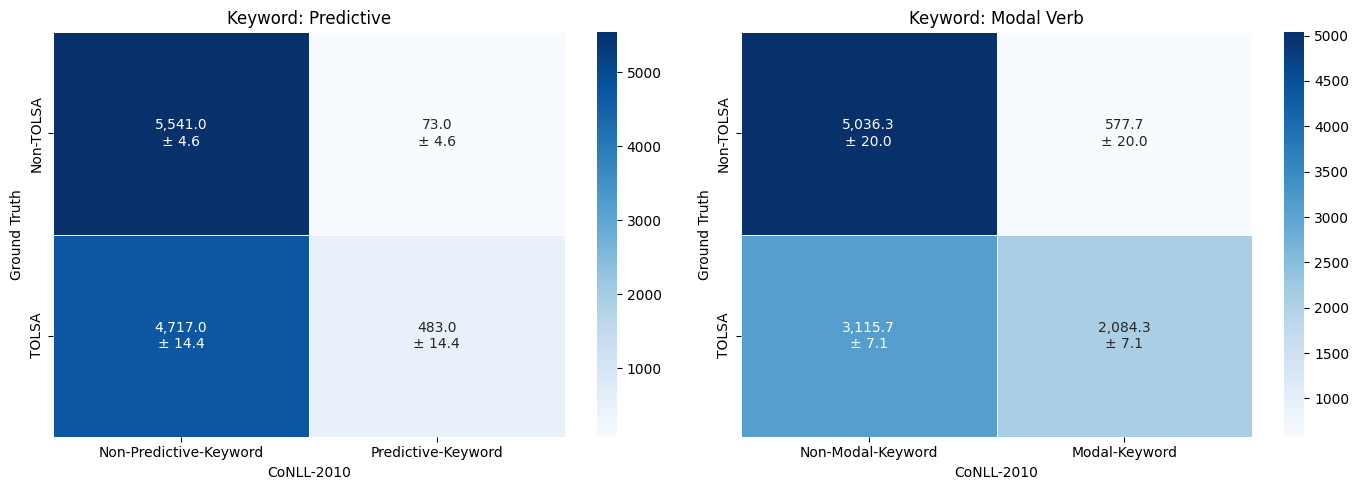

In [32]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

SEEDS = [3, 7, 33]
LABEL_COLUMN = "Ground Truth"

# distribution row name -> (panel title, rule-not-fired label, rule-fired label)
properties = {
    "Verb": ("Keyword: Predictive", "Non-Predictive-Keyword", "Predictive-Keyword"),   # VERBS list
    "Modal Verb": ("Keyword: Modal Verb", "Non-Modal-Keyword", "Modal-Keyword"),       # AUXILIARIES list
}
row_labels = ["Non-TOLSA", "TOLSA"]  # Actual (top to bottom)


def fired_count(dist_df, category):
    """Exact match on the category name, so "Verb" never picks up "Modal Verb"."""
    names = dist_df.iloc[:, 0].astype(str).str.strip()
    return pd.to_numeric(dist_df.loc[names == category].iloc[0, 1])


def label_totals(seed):
    """[Non-TOLSA, TOLSA] row counts over val + test, read from the saved splits."""
    split_dir = base_dir / f"seed{seed}" / "in_domain" / "splits"
    labels = pd.concat(
        [pd.read_csv(split_dir / f"x_y_{split}_set.csv", usecols=[LABEL_COLUMN])
         for split in ("val", "test")]
    )[LABEL_COLUMN].astype(int)
    counts = labels.value_counts()
    return np.array([counts.get(0, 0), counts.get(1, 0)])


def seed_matrix(seed, category):
    """2x2 counts: rows = Actual (Non-TOLSA, TOLSA), columns = rule (not fired, fired)."""
    non_tol_total, tol_total = label_totals(seed)
    non_tol_hit = fired_count(globals()[f"distribution_non_tolsam_seed{seed}"], category)
    tol_hit = fired_count(globals()[f"distribution_tolsam_seed{seed}"], category)
    return np.array([
        [non_tol_total - non_tol_hit, non_tol_hit],
        [tol_total - tol_hit, tol_hit],
    ])


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (category, (title, neg_label, pos_label)) in zip(axes, properties.items()):
    stack = np.stack([seed_matrix(seed, category) for seed in SEEDS])
    mean = stack.mean(axis=0)
    std = stack.std(axis=0, ddof=1)

    annot = np.array([
        [f"{mean[i, j]:,.1f}\n± {std[i, j]:.1f}" for j in range(2)]
        for i in range(2)
    ])

    sns.heatmap(
        mean,
        annot=annot,
        fmt="",
        cmap="Blues",
        linewidths=0.5,
        cbar=True,
        xticklabels=[neg_label, pos_label],
        yticklabels=row_labels,
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("CoNLL-2010")
    ax.set_ylabel("Ground Truth")
    plt.setp(ax.get_yticklabels(), rotation=90, va="center")

plt.tight_layout()
plt.show()